<a href="https://colab.research.google.com/github/Chiamaka05/New/blob/main/materials_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd

file_path = '/content/drive/MyDrive/Machine_Learning/material/Data.csv'
df = pd.read_csv(file_path)

# print(df.shape)
# print(df.info)
print(df.head(5))
df.dropna(axis=1, inplace=True)
df['Sy'] = df['Sy'].astype(str).str.extract(r'([-+]?\d*\.?\d+)')
df['Sy'] = pd.to_numeric(df['Sy'], errors='coerce')
df.describe()

    Std                                ID        Material Heat treatment   Su  \
0  ANSI  D8894772B88F495093C43AF905AB6373  Steel SAE 1015      as-rolled  421   
1  ANSI  05982AC66F064F9EBC709E7A4164613A  Steel SAE 1015     normalized  424   
2  ANSI  356D6E63FF9A49A3AB23BF66BAC85DC3  Steel SAE 1015       annealed  386   
3  ANSI  1C758F8714AC4E0D9BD8D8AE1625AECD  Steel SAE 1020      as-rolled  448   
4  ANSI  DCE10036FC1946FC8C9108D598D116AD  Steel SAE 1020     normalized  441   

    Sy    A5    Bhn       E      G   mu    Ro     pH Desc  HV  
0  314  39.0  126.0  207000  79000  0.3  7860    NaN  NaN NaN  
1  324  37.0  121.0  207000  79000  0.3  7860    NaN  NaN NaN  
2  284  37.0  111.0  207000  79000  0.3  7860    NaN  NaN NaN  
3  331  36.0  143.0  207000  79000  0.3  7860    NaN  NaN NaN  
4  346  35.8  131.0  207000  79000  0.3  7860  550.0  NaN NaN  


,Su,Sy,E,G,mu,Ro
count,1552.000000,1552.000000,1552.000000,1552.000000,1552.000000,1552.000000
mean,572.753222,387.010309,164571.520619,85598.840206,0.302977,6929.843428
std,326.834927,289.482497,56135.405867,125326.800138,0.024590,2115.171710
min,69.000000,28.000000,73000.000000,26000.000000,0.200000,1750.000000
25%,340.000000,205.000000,105000.000000,40000.000000,0.300000,7160.000000
50%,500.000000,305.000000,206000.000000,79000.000000,0.300000,7860.000000
75%,705.000000,470.000000,206000.000000,80000.000000,0.320000,7860.000000
max,2220.000000,2048.000000,219000.000000,769000.000000,0.350000,8930.000000


<Axes: ylabel='Material'>

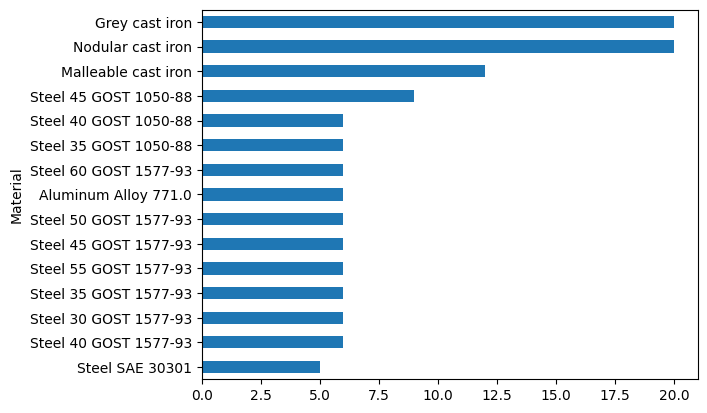

In [ ]:
df['Material'].value_counts().head(15).sort_values().plot(kind='barh')

<Axes: xlabel='Std'>

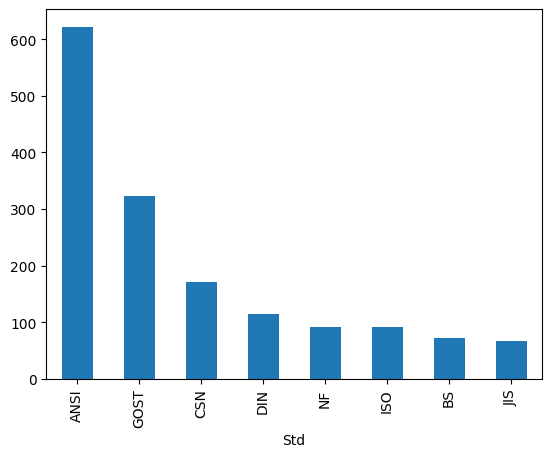

In [ ]:
df['Std'].value_counts().plot(kind='bar')

<Axes: ylabel='Frequency'>

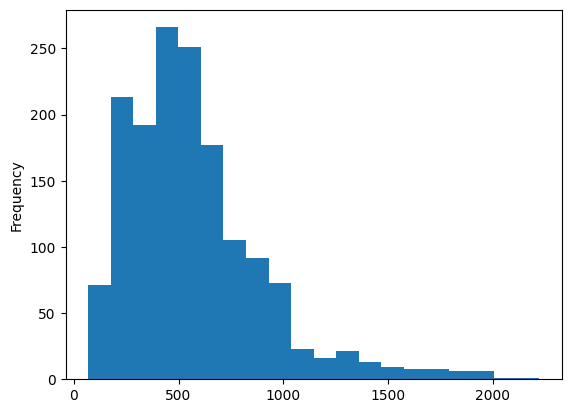

In [ ]:
df['Su'].plot(kind='hist', bins=20)

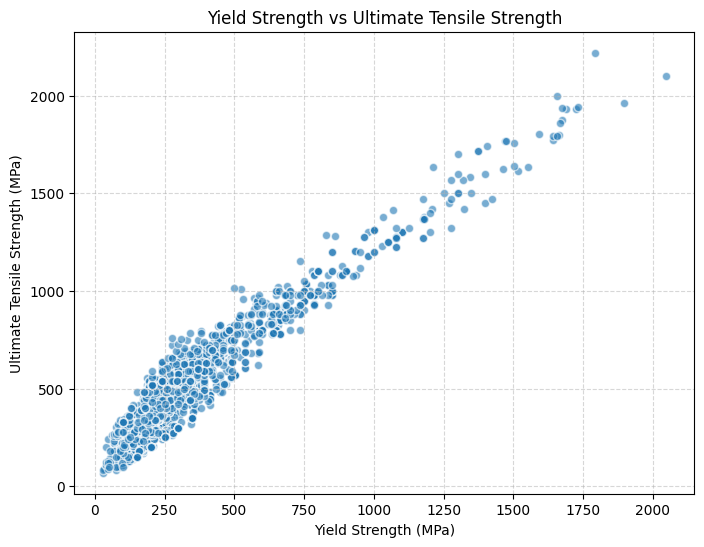

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Ensure Sy and Su are fully numeric (coercing errors to NaN)
df['Sy'] = pd.to_numeric(df['Sy'], errors='coerce')
df['Su'] = pd.to_numeric(df['Su'], errors='coerce')

# Filter out NaN rows for clean plotting
clean_df = df.dropna(subset=['Sy', 'Su'])

plt.figure(figsize=(8, 6))
plt.scatter(clean_df['Sy'], clean_df['Su'], alpha=0.6, edgecolors='w')
plt.xlabel('Yield Strength (MPa)')
plt.ylabel('Ultimate Tensile Strength (MPa)')
plt.title('Yield Strength vs Ultimate Tensile Strength')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

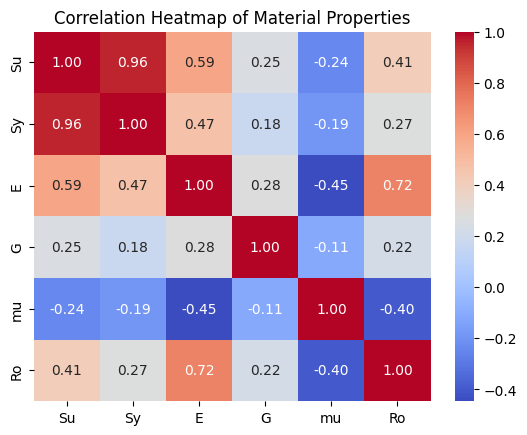

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

cols = ['Su', 'Sy', 'E', 'G', 'mu', 'Ro']

# Convert columns to numeric, turning non-numeric strings (like '280 max') into NaN
for col in cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

corr = df[cols].corr()

sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of Material Properties')
plt.show()

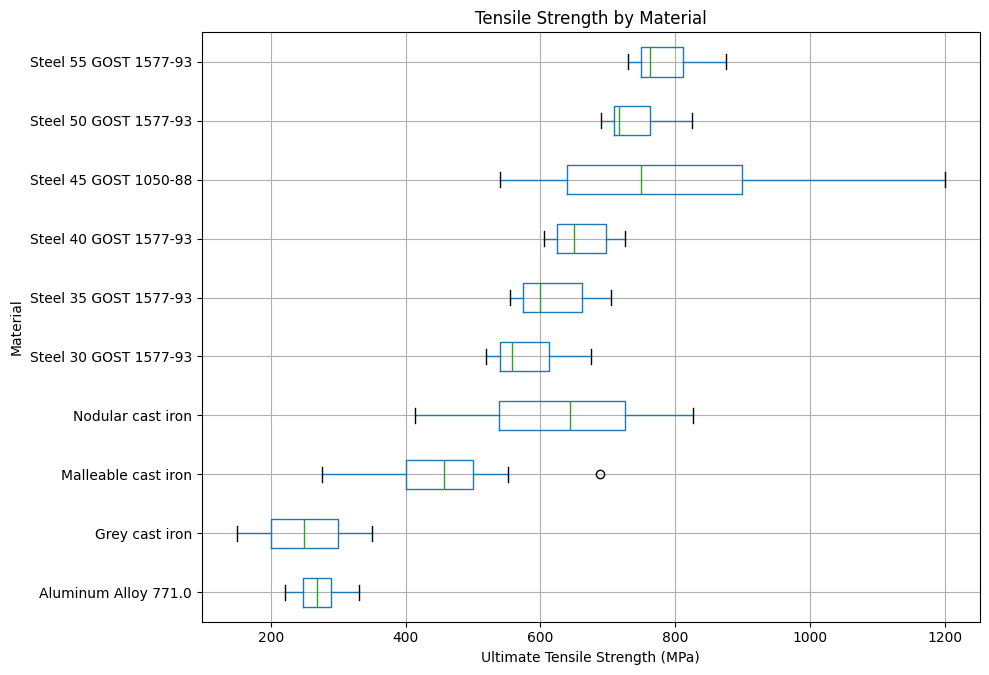

In [ ]:
top_materials = df['Material'].value_counts().head(10).index
data = df[df['Material'].isin(top_materials)]

data.boxplot(
    column='Su',
    by='Material',
    vert=False,
    figsize=(10, 7)
)

plt.title('Tensile Strength by Material')
plt.suptitle('')
plt.xlabel('Ultimate Tensile Strength (MPa)')
plt.ylabel('Material')
plt.tight_layout()
plt.show()

In [ ]:
# Check how many duplicate rows exist in the DataFrame
num_duplicates = df.duplicated().sum()
print(f"Number of duplicate rows: {num_duplicates}")

# If you want to view the actual duplicate rows (if any):
if num_duplicates > 0:
    print(df[df.duplicated()])

Number of duplicate rows: 0


In [ ]:
# Check the data types of all columns in the DataFrame
display(df.dtypes)

# Or for a detailed summary including non-null counts and memory usage
df.info()

,0
Std,object
ID,object
Material,object
Su,int64
Sy,int64
E,int64
G,int64
mu,float64
Ro,int64


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1552 entries, 0 to 1551
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Std       1552 non-null   object 
 1   ID        1552 non-null   object 
 2   Material  1552 non-null   object 
 3   Su        1552 non-null   int64  
 4   Sy        1552 non-null   int64  
 5   E         1552 non-null   int64  
 6   G         1552 non-null   int64  
 7   mu        1552 non-null   float64
 8   Ro        1552 non-null   int64  
dtypes: float64(1), int64(5), object(3)
memory usage: 109.3+ KB


In [ ]:
df['Yield-to-Tensile Ratio'] = df['Sy'] / df['Su']
df['Yield_Strain'] = df['Sy'] / df['E']
df['Specific_Strength'] = df['Sy'] / df['Ro']
df['Modulus_of_Resilience'] = (df['Sy'] ** 2) / (2 * df['E'])
df['Bulk_Modulus'] = df['E'] / (3 * (1 - 2 * df['mu']))
new_features = [
    'Yield-to-Tensile Ratio',
    'Yield_Strain',
    'Specific_Strength',
    'Modulus_of_Resilience',
    'Bulk_Modulus'
]

df[new_features].describe()

,Yield-to-Tensile Ratio,Yield_Strain,Specific_Strength,Modulus_of_Resilience,Bulk_Modulus
count,1552.000000,1552.000000,1552.000000,1552.000000,1552.000000
mean,0.650148,0.002357,0.059082,0.628752,137968.887521
std,0.167207,0.001439,0.040041,1.021646,43094.187406
min,0.199170,0.000380,0.004591,0.005370,53333.333333
25%,0.533886,0.001359,0.031424,0.142157,97222.222222
50%,0.641791,0.001893,0.046501,0.293486,166666.666667
75%,0.772727,0.002941,0.076667,0.656311,171666.666667
max,1.088328,0.009894,0.260560,10.131169,180000.000000


In [ ]:
df['Material'].value_counts()

,count
Material,
Nodular cast iron,20
Grey cast iron,20
Malleable cast iron,12
Steel 45 GOST 1050-88,9
Aluminum Alloy 771.0,6
...,...
Aluminum Alloy Alclad 6061-T451,1
Aluminum Alloy Alclad 6061-T4,1
Aluminum Alloy Alclad 6061-O,1


In [ ]:
unclassified = df.loc[
    df['Material_Family'].isna(),
    'Material'
].unique()

print(unclassified)

[]


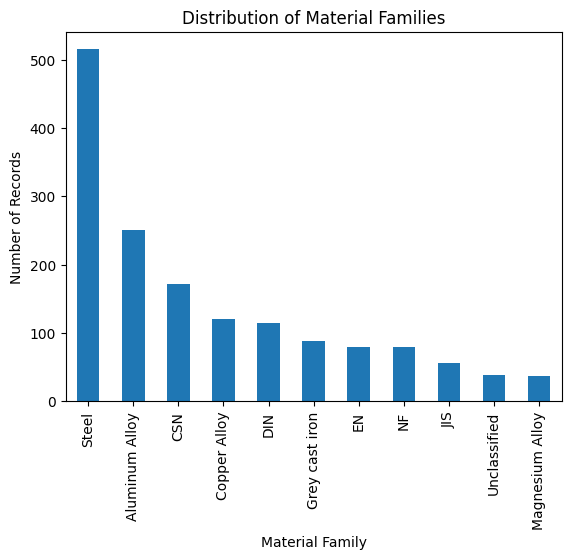

,count
Material_Family,
Steel,515
Aluminum Alloy,251
CSN,172
Copper Alloy,121
DIN,114
Grey cast iron,88
EN,80
NF,80
JIS,56


In [ ]:
df['Material'].value_counts()

def classify_material(material):
    # Handle missing/empty data so 'nan' doesn't trigger the 'en' condition
    if pd.isna(material) or material == '':
        return 'Unclassified'

    material = str(material).lower().strip()

    if 'steel' in material or 'bs' in material:
        return 'Steel'
    elif 'cast iron' in material:
        return 'Grey cast iron'
    elif 'csn' in material:
        return 'CSN'
    elif 'din' in material:
        return 'DIN'
    elif 'nf' in material:
        return 'NF'
    elif 'en' in material:  # Safe now that 'nan' is filtered out
        return 'EN'
    elif 'aluminum' in material:
        return 'Aluminum Alloy'
    elif any(word in material for word in ['copper', 'brass', 'manganese', 'silver', 'special']):
        return 'Copper Alloy'
    elif 'jis' in material:
        return 'JIS'
    elif 'magnesium' in material:
        return 'Magnesium Alloy'
    else:
        return 'Unclassified'

df['Material_Family'] = df['Material'].apply(classify_material)
df['Material_Family'].value_counts().plot(kind='bar')

plt.title('Distribution of Material Families')
plt.xlabel('Material Family')
plt.ylabel('Number of Records')
plt.show()
df['Material_Family'].value_counts()

In [ ]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix)
X = df.drop(columns=['Material',
    'ID',
    'Std',
    'Material_Family',
    'Material_Family_Encoded'])
y = df['Material_Family']
encoder = LabelEncoder()
df['Material_Family_Encoded'] = encoder.fit_transform(
    df['Material_Family']
)

y = df['Material_Family_Encoded']
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
model = RandomForestClassifier(
    n_estimators=300,
    class_weight='balanced',
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Accuracy: 0.7459807073954984

Classification Report:
              precision    recall  f1-score   support

           0       0.94      1.00      0.97        50
           1       0.38      0.42      0.40        12
           2       0.48      0.35      0.41        34
           3       0.92      0.90      0.91        51
           4       0.06      0.04      0.05        23
           5       0.15      0.19      0.17        16
           6       0.86      1.00      0.92        18
           7       0.38      0.56      0.45        16
           8       0.99      0.97      0.98        91

    accuracy                           0.75       311
   macro avg       0.57      0.60      0.58       311
weighted avg       0.74      0.75      0.74       311


Confusion Matrix:
[[50  0  0  0  0  0  0  0  0]
 [ 0  5  1  1  2  3  0  0  0]
 [ 3  3 12  1  5  4  1  4  1]
 [ 0  0  2 46  2  1  0  0  0]
 [ 0  3  4  2  1  7  2  4  0]
 [ 0  0  3  0  4  3  0  6  0]
 [ 0  0  0  0  0  0 18  0  0]
 [ 0  1  3  0

In [ ]:
for i, name in enumerate(encoder.classes_):
    print(i, name)
df.loc[
    df['Material_Family'].isna(),
    'Material'
].value_counts()

0 Aluminum Alloy
1 BS
2 CSN
3 Copper Alloy
4 DIN
5 EN
6 Grey cast iron
7 NF
8 Steel


,count
Material,
